In [2]:
# ===============================
# import libraries
# ===============================
import numpy as np
import pandas as pd
from pathlib import Path
import chartgazing as cg

cg.set_size("square")

In [3]:
# ===============================
# import card data
# ===============================

# set data directory
DATA_DIR = Path("data/sets")

# combine every saved set
pokemon_all = pd.concat(
    [pd.read_csv(path, dtype={"number": str, "product_id": str, "variant": str}, parse_dates=["date"]) for path in DATA_DIR.glob("*.csv")],
    ignore_index=True
)

# additional data on each set
sets_df = pd.read_csv("data/sets_info.csv", parse_dates=["release_date"])
pokemon_all = pokemon_all.merge(sets_df, on="set_slug", how="left")

In [4]:
# ===============================
# clean data
# ===============================
pokemon_all["variant"] = pokemon_all["variant"].fillna("Standard")
pokemon_all["price"] = pokemon_all["price"].replace(0, np.nan)
pokemon_all["date"] = pokemon_all["date"].dt.to_period("M").dt.to_timestamp()
pokemon_all["decade"] = (pokemon_all["release_date"].dt.year // 10) * 10


for col in ["grade", "set_slug", "set_name", "language", "name", "variant"]:
    pokemon_all[col] = pokemon_all[col].astype("category")

In [5]:
# ===============================
# Changes for all cards
# ===============================
GRADE = "Ungraded"
IMAGE_DIR = "images/4x5"
source = "Source: PriceCharting.com"

all_prices = pokemon_all.dropna(subset=["price"])

# TEMP LINE
# priced_cards = all_prices[all_prices["grade"] == GRADE]
priced_cards = all_prices

latest_date = priced_cards["date"].max()
latest_cards = priced_cards[priced_cards["date"] == latest_date]

def fmt(value):
    return f"${value:,.0f}" if value >= 1000 else f"${value:.2f}"

def short_set(set_name):
    return set_name.removeprefix("Pokemon ")

def one_per_card(cards):
    return(
        cards.assign(not_standard=cards["variant"] != "Standard")
        .sort_values(["not_standard", "price"])
        .drop_duplicates(["set_slug", "number", "name"])
    )

In [6]:
# ===============================
# prepare 2026 card price change
# ===============================
cards_2026 = all_prices.assign(date=all_prices["date"] - pd.DateOffset(months=1))
cards_2026 = cards_2026[
    (cards_2026["date"] >= "2026-01-01")
    & (cards_2026["grade"] == GRADE)
]

year_start = cards_2026[cards_2026["date"] == "2026-01-01"].set_index("product_id")["price"]

cards_2026 = cards_2026[cards_2026["product_id"].isin(year_start.index)]

cards_2026["pct_chng"] = (cards_2026["price"] / cards_2026["product_id"].map(year_start) -1) * 100

cards_2026.sort_values(["product_id", "date"])

cards_26 = cards_2026.groupby("date", as_index=False).agg(
    unique_cards = ("product_id", "nunique"),
    PK_pct_chng = ("pct_chng", "median")
)


# ===============================
# import S&P 500 data
# ===============================
sp_500 = pd.read_csv(f"data/S&P_500.csv")

sp_500["Date"] = pd.to_datetime(sp_500["Date"], format="%d/%m/%Y")

sp_500["Change"] = sp_500["Change %"].str.removesuffix("%") 
sp_500 = sp_500[["Date", "Price", "Change"]]

sp_500["Change"] = sp_500["Change"].astype(float)
sp_500["Price"] = sp_500["Price"].str.replace(r"[^\d\.]", "",regex=True).astype(float)

sp_500 = sp_500[sp_500["Date"] >= "2026-01-01"]

sp_500 = sp_500.sort_values(by="Date", ascending=True)

sp_500["SP_pct_chng"] = ((sp_500["Price"] - sp_500["Price"].iloc[0]) / sp_500["Price"].iloc[0]) * 100

sp_500.columns = sp_500.columns.str.lower()


# ===============================
# combined 2026 returns
# ===============================

returns = pd.merge(cards_26, sp_500, on='date')

returns = returns[["date", "PK_pct_chng", "sp_pct_chng"]]

returns = returns.rename(columns={"PK_pct_chng": "Pokémon", "sp_pct_chng": "S&P 500"})

returns = pd.melt(returns, id_vars="date", var_name="category", value_name="pct_change")

returns

,date,category,pct_change
0,2026-01-01,Pokémon,0.000000
1,2026-02-01,Pokémon,2.882537
2,2026-03-01,Pokémon,8.517699
3,2026-04-01,Pokémon,14.285714
4,2026-05-01,Pokémon,19.256491
5,2026-06-01,Pokémon,20.735786
6,2026-07-01,Pokémon,18.107876
7,2026-08-01,Pokémon,26.710695
8,2026-09-01,Pokémon,29.787234
9,2026-01-01,S&P 500,0.000000


In [7]:
# ===============================
# spot-check 1 Oct prices against PriceCharting
# ===============================
from urllib.parse import quote_plus

oct_cards = all_prices[(all_prices["date"] == "2026-01-01") & (all_prices["grade"] == GRADE)].copy()

# spread the sample across price levels so cheap cards that never move don't dominate
oct_cards["tier"] = pd.qcut(oct_cards["price"], 3, labels=["low", "mid", "high"])

sample = oct_cards.groupby("tier", observed=True).sample(n=3, random_state=None)

sample["search"] = (
    "https://www.pricecharting.com/search-products?type=prices&q="
    + (sample["set_name"].astype(str) + " " + sample["name"].astype(str) + " " + sample["number"]).map(quote_plus)
)

sample[["tier", "set_name", "name", "number", "variant", "product_id", "price", "search"]]


,tier,set_name,name,number,variant,product_id,price,search
1398152,low,Pokemon Black Bolt,braviary,78,Reverse,10031574,0.10,https://www.pricecharting.com/search-products?...
3427054,low,Pokemon Destined Rivals,ethan's adventure,165,Reverse Holo,9433106,0.32,https://www.pricecharting.com/search-products?...
451097,low,Pokemon 2020 Battle Academy,cynthia,119,Standard,5421460,0.29,https://www.pricecharting.com/search-products?...
7057154,mid,Pokemon Mysterious Treasures,vulpix,107,Standard,920731,1.48,https://www.pricecharting.com/search-products?...
11236984,mid,Pokemon Surging Sparks,rufflet,152,Reverse Holo,7812948,1.30,https://www.pricecharting.com/search-products?...
10301907,mid,Pokemon Shining Fates,piers,69,Standard,1341546,2.01,https://www.pricecharting.com/search-products?...
5604998,high,Pokemon Gym Challenge,koga's kakuna,47,1st Edition,1450241,4.99,https://www.pricecharting.com/search-products?...
2822618,high,Pokemon Crown Zenith,psychic energy,156,Holo,4637052,3.94,https://www.pricecharting.com/search-products?...
11091701,high,Pokemon Supreme Victors,butterfree fb,17,Standard,1287064,6.44,https://www.pricecharting.com/search-products?...


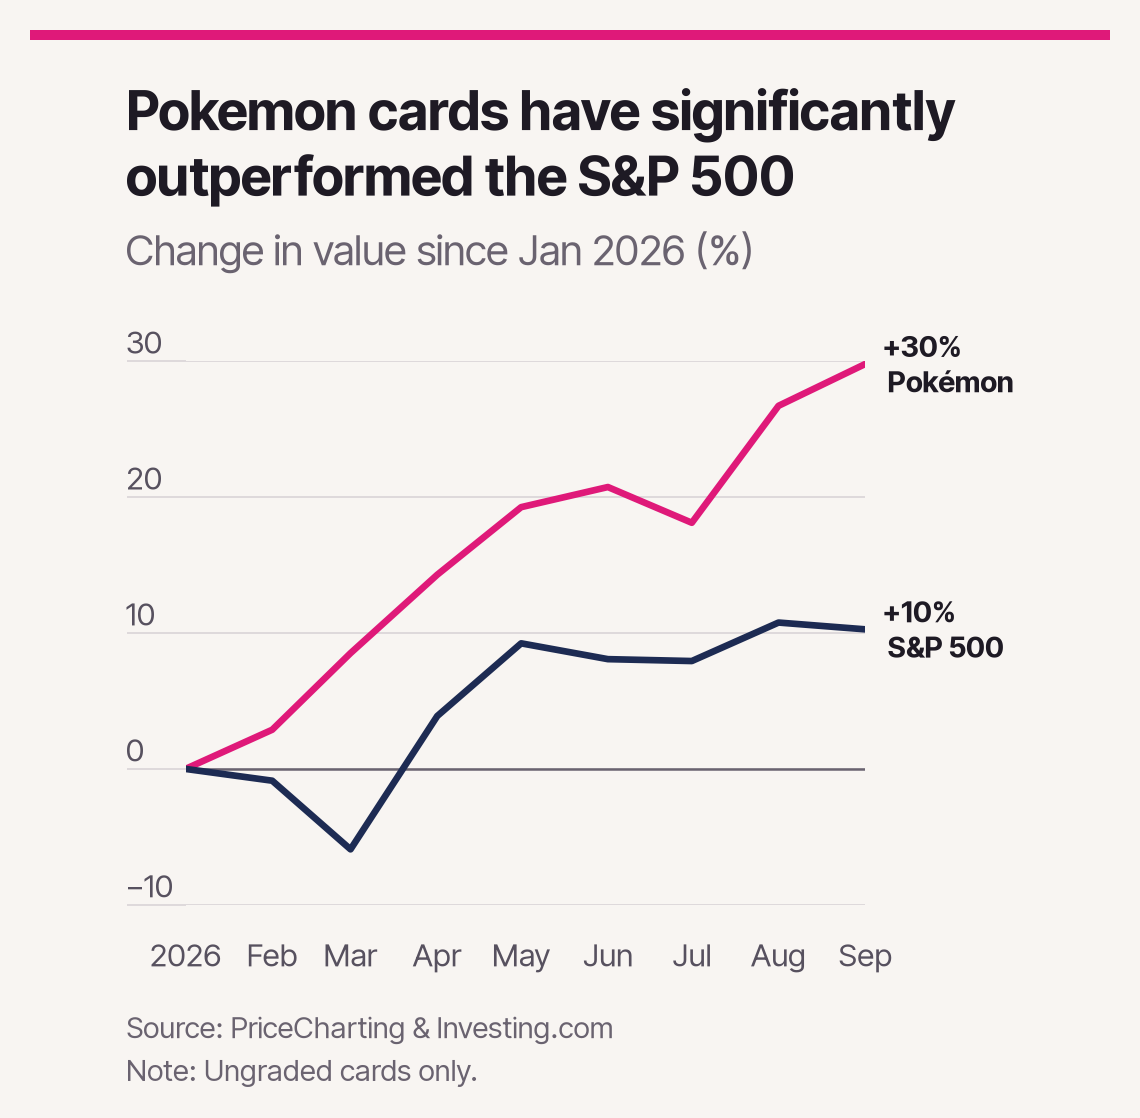

In [8]:
CHART_DIR = Path("charts/")

fig, ax = cg.line(returns, x="date", y="pct_change", group="category",
                  title="Pokemon cards have significantly outperformed the S&P 500",
                  subtitle="Change in value since Jan 2026 (%)",
                  source="Source: PriceCharting & Investing.com",
                  note="Note: Ungraded cards only.",
                  labels=False)

ax.set_yticks([-10, 0, 10, 20, 30, 40, 50])

last = returns.sort_values("date").groupby("category").last()

cg.label_ends(ax, last["pct_change"].to_dict(), fmt=lambda name, value: f"{value:+.0f}% \n {name}")

cg.save(fig, CHART_DIR / "SP500.png")


            cards  median_price  total_value  value_share  prop_cards
band                                                                 
Bottom 50%  95039         10.50    886129.06     0.016313    0.501245
50-90%      75616         44.15   5152989.19     0.094864    0.398806
Top 10%     17059        589.00  16877977.13     0.310715    0.089971
Top 1%       1892       8800.00  31402668.44     0.578108    0.009979


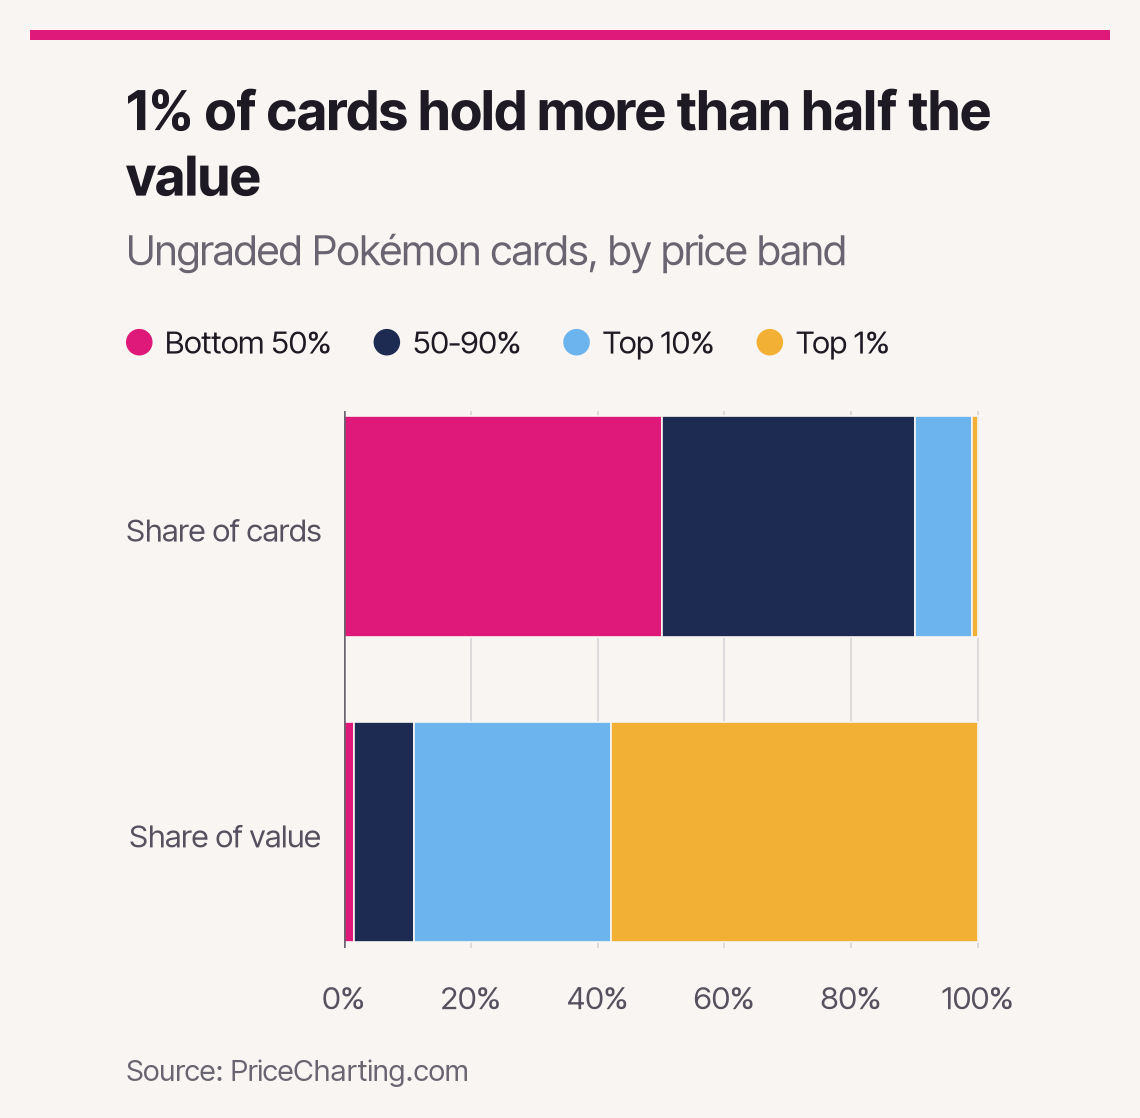

In [73]:
value_distribution = (
    # latest_cards[latest_cards["grade"] == GRADE]                      
    latest_cards.assign(
        band = pd.qcut(
            latest_cards.price, 
            q=[0, 0.50, 0.90, 0.99, 1], 
            labels=["Bottom 50%", "50-90%", "Top 10%", "Top 1%"])
    )
)

# summary = value_distribution.groupby("band")["price"].agg(["count", "median", "sum"])

summary = (
    value_distribution.groupby("band", observed=True)
    .agg(cards=("price", "count"), median_price = ("price", "median"), total_value=("price", "sum"))
    .assign(value_share=lambda d: d["total_value"] / d["total_value"].sum())
)

summary["prop_cards"] = summary["cards"] / summary["cards"].sum()

print(summary.head(5))

chart_df = (
    summary.reset_index()
    .melt(id_vars="band", value_vars=["prop_cards", "value_share"],
          var_name="bar", value_name="share")
    .replace({"bar": {"prop_cards": "Share of cards", "value_share": "Share of value"}})
    )


fix, ax = cg.stacked_bar(chart_df, x="share", y="bar", group="band", normalise=True,
                         title="1% of cards hold more than half the value",
                         subtitle="Ungraded Pokémon cards, by price band",
                         source=source)

In [46]:
prices = latest_cards["price"]

thresholds = prices.quantile([0.5, 0.9, 0.99, 0.999])

thresholds 
share_under_5 = (prices < 5).mean()

share_under_5
thresholds, share_under_5


(0.500       22.00000
 0.900      253.00000
 0.990     4750.00000
 0.999    30039.89895
 Name: price, dtype: float64,
 np.float64(0.15531154077402615))

In [ ]:
latest_cards